In [ ]:
import pandas as pd
from banco import conectar
import matplotlib.pyplot as plt

In [8]:
# Função para consultar o banco de dados e retornar um DataFrame
def consultar(sql):
    """Executa uma query e retorna DataFrame."""
    conexao = conectar()
    if conexao is None:
        print("Erro ao conectar")
        return None
    
    try:
        df = pd.read_sql(sql, conexao)
        return df
    
    except Exception as e:
        print(f"Erro na query: {e}")
        conexao.close()
        return None
    
    finally:
        conexao.close()

# Função para formatar valores como moeda brasileira
def reais(valor):
    """Formata um número como moeda brasileira."""
    return f"R$ {valor:,.2f}".replace(',', '_').replace('.', ',').replace('_', '.')

Quais os 5 órgãos com maior custo total?

In [12]:
# Consulta SQL para obter os 5 órgãos superiores com maior custo total
sql_top_orgaos = """
SELECT
    nome_orgao_superior AS orgao,
    SUM(valor_total) AS custo_total
FROM silver_viagem
WHERE valor_total IS NOT NULL
GROUP BY nome_orgao_superior
ORDER BY custo_total DESC
LIMIT 5;
"""

df_top_orgaos = consultar(sql_top_orgaos)

# Formata a coluna como moeda brasileira
df_top_orgaos["custo_total_formatado"] = (
    df_top_orgaos["custo_total"].apply(reais)
)

display(df_top_orgaos[['orgao', 'custo_total_formatado']])

C:\Users\heloi\AppData\Local\Temp\ipykernel_38412\3756829756.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conexao)


,orgao,custo_total_formatado
0,Ministério da Justiça e Segurança Pública,"R$ 486.933.121,65"
1,Ministério da Defesa,"R$ 156.070.304,49"
2,Ministério da Educação,"R$ 111.291.349,34"
3,Ministério do Meio Ambiente e Mudança do Clima,"R$ 49.697.710,16"
4,Ministério da Previdência Social,"R$ 40.417.309,06"


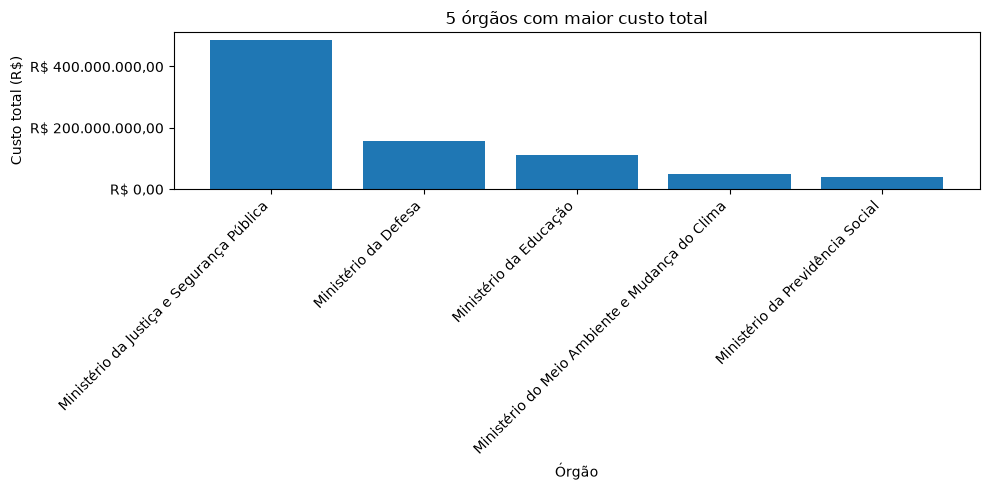

In [19]:
# Gráfico de barras dos 5 órgãos com maior custo total
plt.figure(figsize=(10, 5))

plt.bar(
    df_top_orgaos["orgao"],
    df_top_orgaos["custo_total"]
)

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: reais(x))
)

plt.title("5 órgãos com maior custo total")
plt.xlabel("Órgão")
plt.ylabel("Custo total (R$)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Quais os 3 destinos com maior custo médio por viagem?

In [16]:
# Realiza a consulta SQL para obter os 3 destinos com maior custo médio
sql_destino = """
WITH destinos_viagens AS (
    SELECT DISTINCT
        id_viagem,
        destino_cidade
    FROM silver_trecho
    WHERE
        destino_cidade IS NOT NULL
        AND TRIM(destino_cidade) <> ''
)

SELECT
    t.destino_cidade AS destino,
    AVG(v.valor_total) AS custo_medio,
    COUNT(*) AS quantidade_viagens
FROM destinos_viagens t
INNER JOIN silver_viagem v
    ON t.id_viagem = v.id_viagem
WHERE v.valor_total IS NOT NULL
GROUP BY t.destino_cidade
ORDER BY custo_medio DESC
LIMIT 3;
"""

df_top_destinos = consultar(sql_destino)

# Formata a coluna como moeda brasileira
df_top_destinos["custo_medio_formatado"] = (
    df_top_destinos["custo_medio"].apply(reais)

)

display(df_top_destinos[['destino', 'custo_medio_formatado']])

C:\Users\heloi\AppData\Local\Temp\ipykernel_38412\3756829756.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conexao)


,destino,custo_medio_formatado
0,Tejupá,"R$ 115.175,00"
1,Chavantes,"R$ 114.557,01"
2,Teolândia,"R$ 109.322,50"


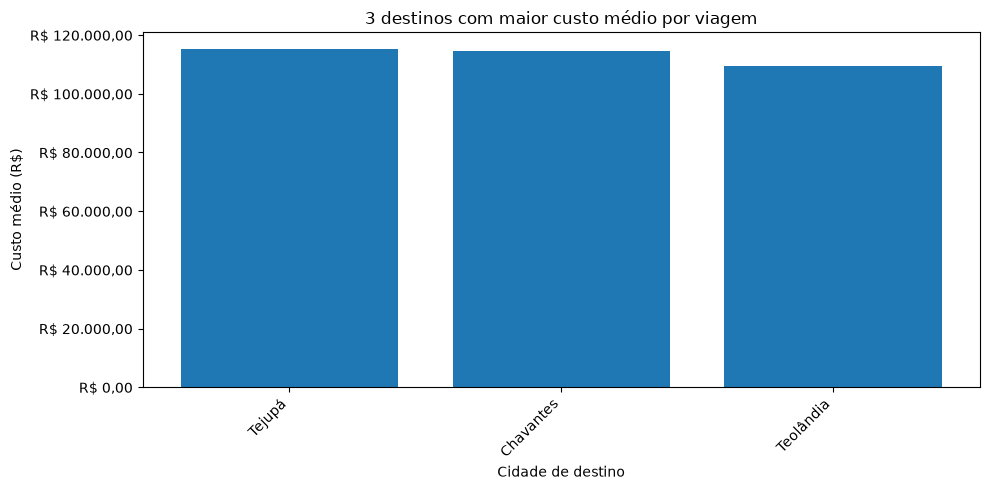

In [17]:
# Gráfico de barras dos 3 destinos com maior custo médio
plt.figure(figsize=(10, 5))

plt.bar(
    df_top_destinos["destino"],
    df_top_destinos["custo_medio"]
)

plt.title("3 destinos com maior custo médio por viagem")
plt.xlabel("Cidade de destino")
plt.ylabel("Custo médio (R$)")

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: reais(x))
)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()